# MAB (Multi-Armed Bandit)? How Do You Actually Use It?

We simulate a Multi-Armed Bandit, the thing that **finds the best option on its own**, using
**Thompson Sampling** (Bayesian, Beta distributions). Each banner gets a 'true click probability' that the
algorithm never sees; it balances exploration and exploitation to home in on the best banner anyway.

Practice flow:
- **9.5.1.** Basic Thompson Sampling: how the Beta distributions converge and impressions concentrate on the best banner
- **9.5.2.** A/B test vs MAB: cumulative regret of a fixed-split A/B test vs MAB (putting a number on the cost of an experiment)
- **9.5.3.** α × Coefficient: separating the distributions of banners with similar, low CTRs with a coefficient
- **9.5.4.** Discounted Thompson Sampling: adapting when the best option changes over time (seasonality)

> This chapter has no data files. The banners' 'true probabilities' are set in code and the notebook runs the
> simulation itself, so you can watch how each algorithm reacts while knowing the right answer. Swap the probability
> arrays at the top of each code cell (`BANNER_PROBABILITIES`, `PROBS`, `CTR`) for your own service's numbers and
> re-run, and you get an immediate feel for convergence speed and opportunity cost in your situation.

## Setup

The first cell below installs the dependencies. The simulation is reproducible via `np.random.seed(42)`.

In [1]:
# Install dependencies (skips quickly if already installed)
# The %pip magic installs into the current kernel environment, so it works without PATH issues.
%pip install -q -r requirements.txt

Note: you may need to restart the kernel to use updated packages.


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import beta

np.random.seed(42)   # reproducibility

# --- Shared chart style for the book (consistent palette, grid, spines) ---
PALETTE = ["#1f9d78", "#3b4556", "#d97706", "#6b7380"]  # green, slate, amber, muted
plt.rcParams.update({
    "axes.prop_cycle": plt.cycler(color=PALETTE),
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "axes.grid.axis": "y", "grid.alpha": 0.3,
    "figure.dpi": 150, "legend.frameon": False,
})

## 9.5.1. Basic Thompson Sampling

We treat each banner's click (reward) probability not as a single number but as a **distribution**. Each reward
outcome (0/1) is added straight into the α (rewards + 1) and β (non-rewards + 1) of a **Beta distribution
Beta(α, β)** (conjugacy), and as data accumulates the variance shrinks and the probability density gathers around
the true probability. On every trial we **draw a sample from each banner's distribution and show the banner with the
largest sample**, then update that banner's distribution with the observed reward. Because we use samples from the
distributions, exploration and exploitation blend together naturally.

In [3]:
NUM_TRIALS = 2000
BANNER_PROBABILITIES = [0.2, 0.5, 0.75]   # each banner's 'true' click probability (unknown to the algorithm)


class Banner:
    def __init__(self, p):
        self.p = p      # true reward probability (known only to the simulation environment, not the algorithm)
        self.a = 1      # Beta distribution α (number of rewards + 1)
        self.b = 1      # Beta distribution β (number of non-rewards + 1)
        self.N = 0      # total number of times this banner was selected (shown)

    def show(self):       # show the banner and return whether it was clicked (1 with probability p, else 0)
        return np.random.random() < self.p

    def sample(self):     # draw one sample from the current Beta distribution (this is where explore/exploit balance comes from)
        return np.random.beta(self.a, self.b)

    def update(self, x):  # update the distribution parameters with the observed reward (x)
        self.a += x
        self.b += 1 - x
        self.N += 1

We create three banners, simulate 2,000 impressions, and plot how each banner's Beta distribution narrows at several checkpoints along the way.

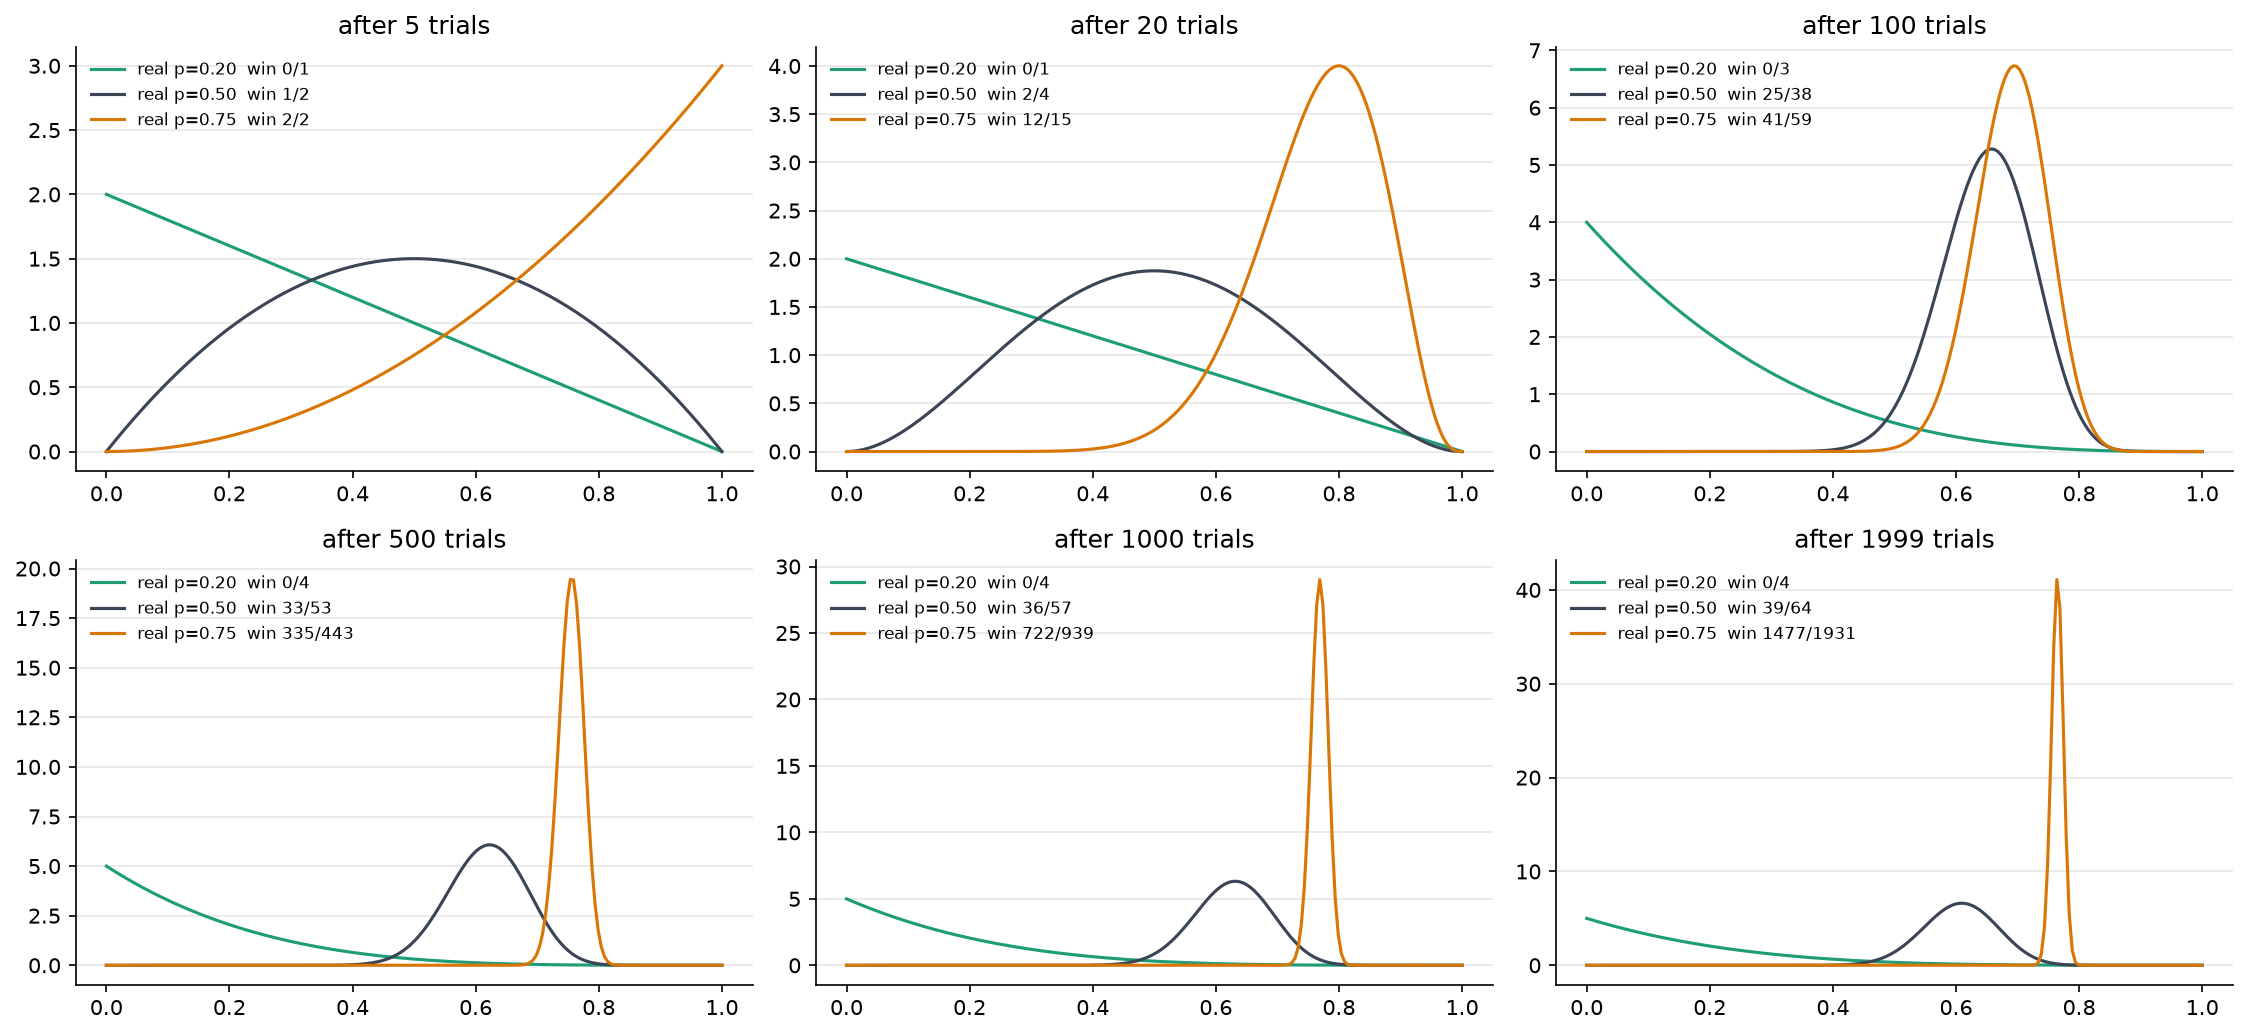

total reward earned: 1516.0
overall win rate   : 0.758
times each selected : [4, 64, 1932]


In [4]:
banners = [Banner(p) for p in BANNER_PROBABILITIES]
checkpoints = [5, 20, 100, 500, 1000, 1999]   # trials at which to inspect the distributions
rewards = np.zeros(NUM_TRIALS)

fig, axes = plt.subplots(2, 3, figsize=(15, 7))
x = np.linspace(0, 1, 200)
for i in range(NUM_TRIALS):
    j = np.argmax([b.sample() for b in banners])   # Thompson Sampling: pick the banner with the largest sample
    if i in checkpoints:
        ax = axes.ravel()[checkpoints.index(i)]
        for b in banners:
            ax.plot(x, beta.pdf(x, b.a, b.b), label=f"real p={b.p:.2f}  win {int(b.a - 1)}/{int(b.N)}")
        ax.set_title(f"after {i} trials"); ax.legend(fontsize=8)
    x_reward = banners[j].show()
    rewards[i] = x_reward
    banners[j].update(x_reward)
plt.tight_layout(); plt.show()

print("total reward earned:", rewards.sum())
print("overall win rate   :", round(rewards.sum() / NUM_TRIALS, 3))
print("times each selected :", [int(b.N) for b in banners])

The lowest-probability banner (0.2) quickly loses its share of impressions as learning proceeds; for a while impressions
alternate between the 0.5 and 0.75 banners, and toward the end they concentrate on the highest-probability banner (0.75).
Impressions of the other banners are kept to the minimum needed for early exploration, and the overall win rate converges
close to the best banner's probability. (The printed numbers depend on the seed.)

## 9.5.2. A/B Test vs MAB

A traditional A/B test splits traffic at a fixed ratio and keeps that split for the whole experiment. Traffic keeps
flowing to the underperforming variants too, so the **cost of the experiment (opportunity loss)** piles up. Using the
purchase-conversion example from book section 9.2.1 (Table 9.1: control 5% / variant A 7% / variant B 1%), we compare
the **cumulative regret** (loss relative to the optimal arm) of a fixed 1/3 split A/B test and Thompson Sampling.

In [5]:
PROBS = np.array([0.05, 0.07, 0.01])   # control / variant A / variant B
OPT = PROBS.max()                       # optimal (= variant A, 7%)
N = 2000


def run_ab(probs, n):
    # Fixed 1/3 equal split: each impression picks a variant uniformly at random
    arms = np.random.randint(len(probs), size=n)
    reward = (np.random.random(n) < probs[arms]).sum()
    return arms, reward


def run_ts(sched, n, gamma=None, decay_every=50):
    # Thompson Sampling. sched(i) = the 'true' probabilities at the i-th impression (they change over time in 9.5.4)
    # If gamma is given, past evidence is discounted every decay_every impressions (Discounted TS in 9.5.4)
    k = len(sched(0))
    a = np.ones(k); b = np.ones(k)
    arms = np.zeros(n, dtype=int); reward = np.zeros(n)
    for i in range(n):
        probs = sched(i)
        if gamma and i > 0 and i % decay_every == 0:
            a = 1 + gamma * (a - 1); b = 1 + gamma * (b - 1)   # variance up -> re-exploration
        j = int(np.argmax(np.random.beta(a, b)))
        x = int(np.random.random() < probs[j])
        a[j] += x; b[j] += 1 - x
        arms[i] = j; reward[i] = x
    return arms, reward

We run both methods for 2,000 trials on the same scenario and compare the cumulative expected clicks missed relative to the optimal variant (A), i.e. the regret.

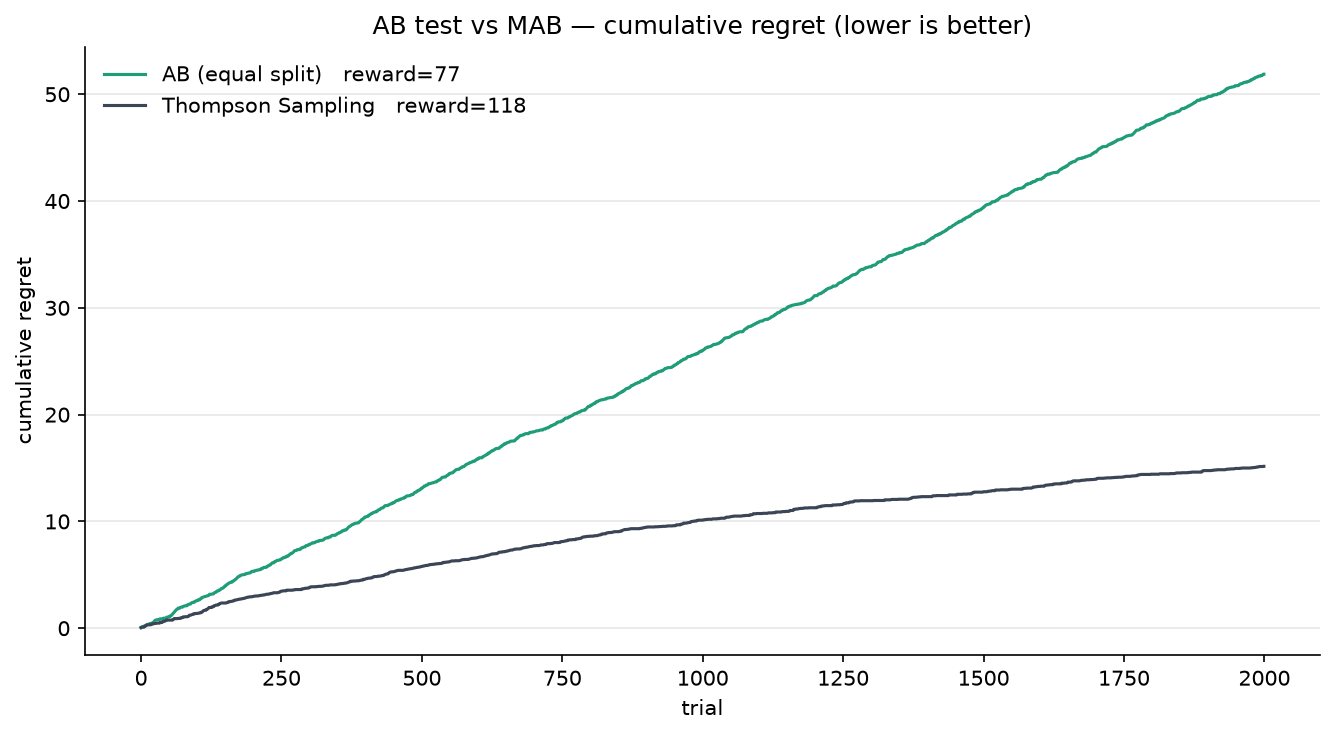

AB  total reward: 77
MAB total reward: 118


In [6]:
ab_arms, ab_reward = run_ab(PROBS, N)
ts_arms, ts_r = run_ts(lambda i: PROBS, N)
ab_regret = np.cumsum(OPT - PROBS[ab_arms])   # cumulative expected clicks missed relative to the optimal variant
ts_regret = np.cumsum(OPT - PROBS[ts_arms])
ts_reward = int(ts_r.sum())

plt.figure(figsize=(9, 5))
plt.plot(ab_regret, label=f"AB (equal split)   reward={ab_reward}")
plt.plot(ts_regret, label=f"Thompson Sampling   reward={ts_reward}")
plt.xlabel("trial"); plt.ylabel("cumulative regret")
plt.title("AB test vs MAB — cumulative regret (lower is better)")
plt.legend(); plt.tight_layout(); plt.show()

print(f"AB  total reward: {ab_reward}")
print(f"MAB total reward: {ts_reward}")

The fixed-split A/B test's cumulative regret grows almost linearly (it keeps spending traffic on the underperforming
variant B), whereas Thompson Sampling quickly shifts traffic to the optimal variant and its regret curve flattens out.
The cumulative reward is also higher for MAB. If an A/B test is "explore briefly, then exploit forever," MAB keeps
weighing exploration against exploitation the whole time.

One caveat: the A/B test in this simulation keeps the equal split for all 2,000 trials. A real A/B test would send
traffic to the winner once the experiment ends, so the opportunity cost that opens up here should be read as the
**cost that accrues 'during the experiment period'**. The more variants you test, and the more often you repeat
experiments, the more of this per-period cost accumulates. That is the experiment cost discussed in book section 9.2.1.

## 9.5.3. α × Coefficient

When click-through rates are **low** (say 0.3-1%) and the differences between banners are **small** (say 0.9% vs 0.6%
vs 0.3%), clicks (rewards) are rare, so **α stays far smaller than β**. As a result all the Beta distributions crowd
together near 0 and overlap almost entirely; the samples lose their discriminating power and the better banner fails to
win enough impressions. This is exactly where a coefficient helps. If on each reward you **multiply the increment
to α by a coefficient** (e.g. +15 instead of +1), the rare click signal is amplified, the distribution means spread apart,
and the samples separate cleanly. (Conversely, when CTR is high and α is on the same scale as β, the distributions are
already well separated and the coefficient adds little.)

Keep in mind that this is a separation heuristic that deliberately inflates the mean, so the estimates are not the real
CTR. Multiplying online on every impression can also lock in early luck, so it is safer to apply it on top of batch
aggregates collected over some period.

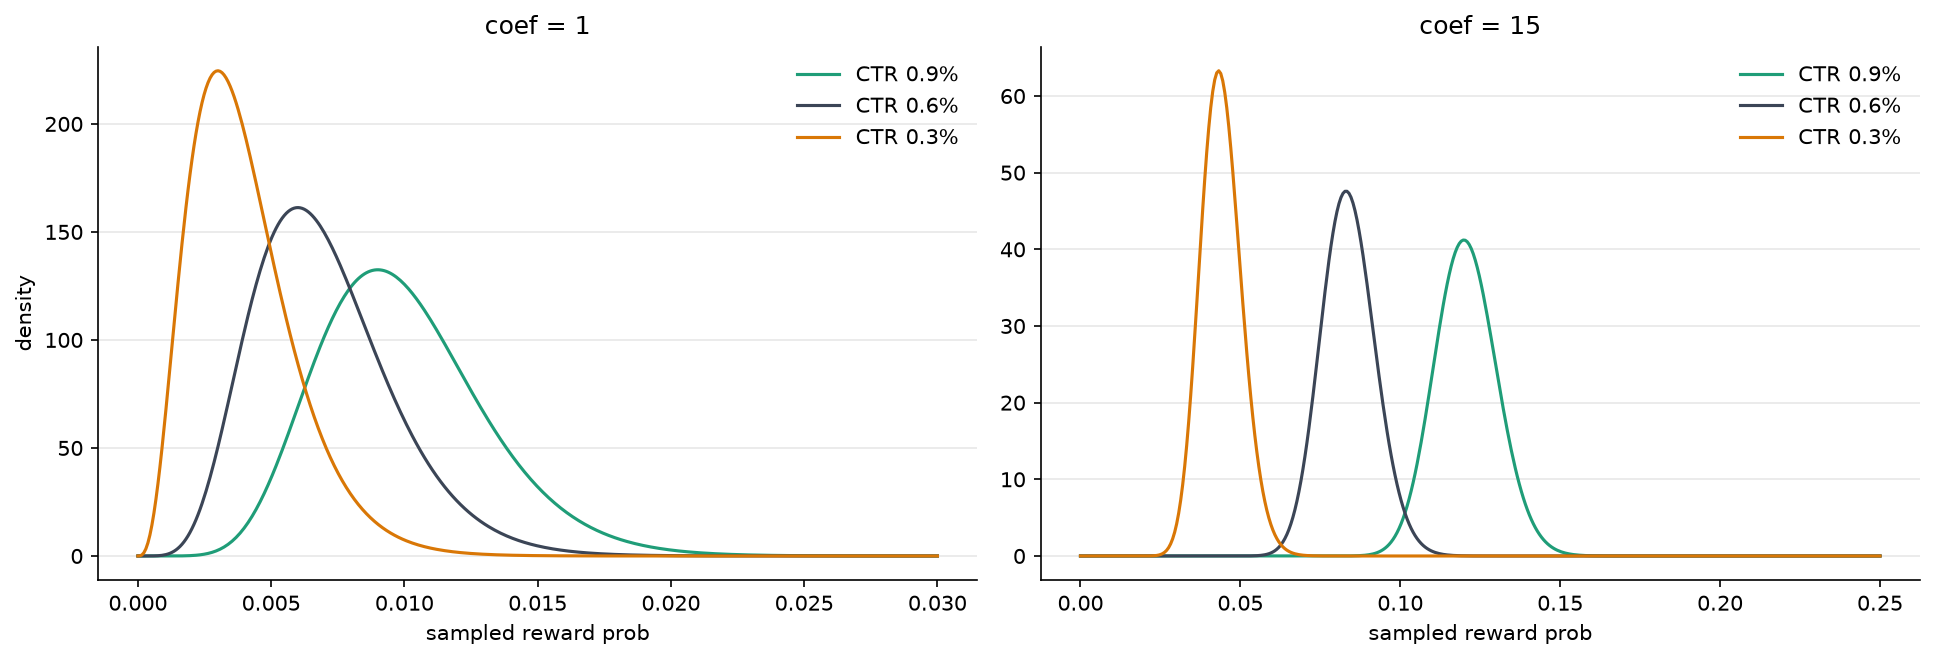

true CTR (%)             : [0.9, 0.6, 0.3]
plain (coef=1) exposure% : [75.4, 21.7, 3.0]


coef=15        exposure% : [99.8, 0.2, 0.0]


In [7]:
CTR = np.array([0.009, 0.006, 0.003])   # low, closely spaced click-through rates (0.9% / 0.6% / 0.3%)
IMPR = 1000                              # impressions, assuming each banner was shown equally often
wins = (CTR * IMPR).round().astype(int)     # expected clicks under equal exposure: [9, 6, 3] -> alpha << beta
losses = IMPR - wins

def make_beta(coef):
    return 1 + coef * wins, 1 + losses    # on each reward (click), add the coefficient (instead of 1) to alpha

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for ax, coef, xmax in zip(axes, [1, 15], [0.03, 0.25]):
    a, b = make_beta(coef)
    xx = np.linspace(0, xmax, 400)
    for k, p in enumerate(CTR):
        ax.plot(xx, beta.pdf(xx, a[k], b[k]), label=f"CTR {p:.1%}")
    ax.set_title(f"coef = {coef}"); ax.set_xlabel("sampled reward prob"); ax.legend()
axes[0].set_ylabel("density")
plt.tight_layout(); plt.show()

# Draw many samples from each distribution and measure how often each one is the maximum (= gets the impression)
def exposure_share(coef, draws=20000):
    a, b = make_beta(coef)
    s = np.random.beta(a[:, None], b[:, None], size=(len(CTR), draws))
    return np.bincount(s.argmax(axis=0), minlength=len(CTR)) / draws

print("true CTR (%)             :", (CTR * 100).round(1).tolist())
print("plain (coef=1) exposure% :", (exposure_share(1) * 100).round(1).tolist())
print("coef=15        exposure% :", (exposure_share(15) * 100).round(1).tolist())

With plain TS (coef=1) the three distributions overlap near 0 and about a quarter of the impressions leak to the
second- and third-ranked banners, whereas with the coefficient the means spread apart and nearly all impressions
concentrate on the highest-CTR banner (0.9%). Leaving the distributions overlapping can slow learning down or let the
opportunity cost keep growing; that is why book section 9.4.2 introduces the coefficient.

## 9.5.4. Discounted Thompson Sampling

In an environment where **the best option changes over time**, such as with seasonality, simply accumulating data lets a
banner that used to be good stay on top through sheer inertia. To give recent data more weight, we periodically discount
the 'accumulated evidence' in α and β by a factor below 1 (the variance widens, which opens up room to explore again),
and the algorithm adapts to the change quickly. Below is an environment where the best banner flips at trial 1000.

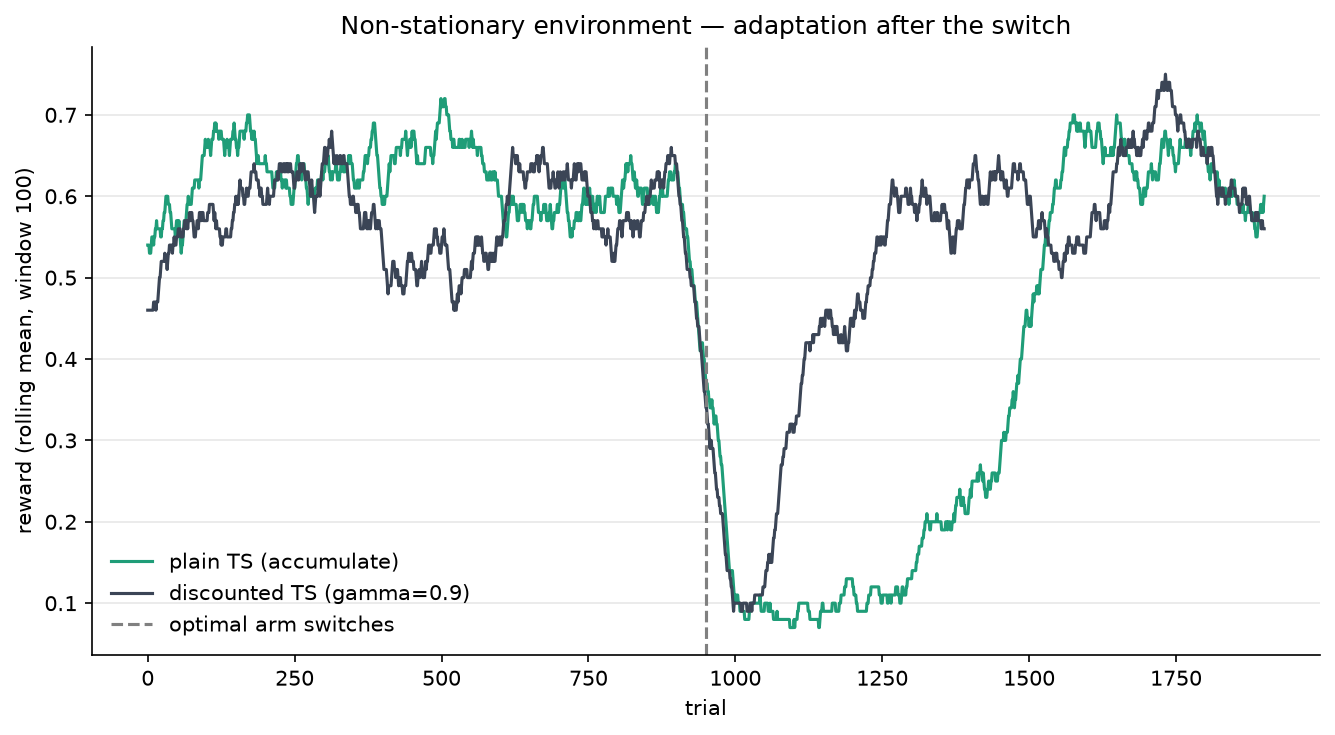

phase 2 reward — plain: 367, discounted: 510


In [8]:
SCHED = lambda i: np.array([0.6, 0.3, 0.1]) if i < 1000 else np.array([0.1, 0.3, 0.6])
N4 = 2000

_, r_plain = run_ts(SCHED, N4)               # just accumulate the data
_, r_disc = run_ts(SCHED, N4, gamma=0.9)     # every 50 impressions, multiply α and β by 0.9 to discount past evidence

w = 100
roll = lambda r: np.convolve(r, np.ones(w) / w, mode="valid")
plt.figure(figsize=(9, 5))
plt.plot(roll(r_plain), label="plain TS (accumulate)")
plt.plot(roll(r_disc), label="discounted TS (gamma=0.9)")
plt.axvline(1000 - w // 2, color="gray", ls="--", label="optimal arm switches")
plt.xlabel("trial"); plt.ylabel(f"reward (rolling mean, window {w})")
plt.title("Non-stationary environment — adaptation after the switch")
plt.legend(); plt.tight_layout(); plt.show()

print(f"phase 2 reward — plain: {r_plain[1000:].sum():.0f}, discounted: {r_disc[1000:].sum():.0f}")

Before the switch the two behave similarly, but once the best banner changes, discounted TS quickly moves over to the
new optimum and earns a higher reward in the second phase. Plain TS, which only accumulates, holds on to the formerly
best banner for quite a while.

## Wrapping up: reality beyond the algorithm, and the right moment

There are practical concerns that have nothing to do with the algorithm. For example, if some banners (direct ad deals,
say) must be guaranteed a certain number of impressions regardless of their click-through rate, it is wise to build
**a structure that can force the exposure ranking** into the design from the start: those banners skip sampling and get
fixed exposure, and the sampled ranking applies only to the rest.

If your organization's data maturity is low, it may be hard to introduce a sophisticated algorithm in one go. There may
be more important things to do, or you may need to build more trust within the organization first. Still, if you keep an
eye out for openings, the right moment will come.